# OCR con PaddleOCR · Leer documentos peruanos difíciles

Buena parte de los datos del Perú no vive en un CSV: vive en resoluciones escaneadas, recibos,
libros de actas y fotos tomadas con el celular. El **OCR** (reconocimiento óptico de
caracteres) convierte esas imágenes en texto que `pandas` puede procesar.

Usaremos [PaddleOCR](https://github.com/PaddlePaddle/PaddleOCR) sobre nueve documentos
peruanos, ordenados de fácil a casi imposible:

| # | Documento | Año | Qué lo hace difícil |
|---|---|---|---|
| 1 | Resolución de alcaldía de Mache (La Libertad) | 2016 | nada: impreso moderno, nuestro punto de partida |
| 2 | Billete de 500 000 intis | 1988 | tipografía ornamental, texto vertical, fondo recargado |
| 3 | Placa de la Calle Capón, Lima | 2010 | foto en la calle: perspectiva, sombras, texto de fondo |
| 4 | Pizarra de menú, Lince | 2010 | letra a mano con tiza, tres columnas |
| 5 | *Mercurio Peruano* | 1791 | imprenta colonial, tinta corrida, ortografía antigua |
| 6 | Recibo de la Peruvian Telephone Company | 1895 | formulario impreso llenado a mano |
| 7 | Tarjeta de Ricardo Palma | 1912 | cursiva de puño y letra |
| 8 | Acta de la Independencia | 1821 | manuscrito de hace dos siglos, en baja resolución |
| 9 | Cartel «Picante de cuy», Junín | 2007 | rótulo pintado a mano |

**Al terminar podrás:**

1. Aplicar OCR a una imagen con tres líneas de código y entender qué devuelve.
2. Usar la GPU de una Mac para que corra decenas de veces más rápido.
3. Medir cuánto se equivoca un OCR, en lugar de juzgarlo a ojo.
4. Elegir entre un OCR clásico y un modelo de visión-lenguaje según el documento.
5. Convertir imágenes en una tabla de datos lista para analizar.

## 0 · Preparación

```bash
uv sync --group docai
```

La primera ejecución descarga los modelos (unos 2,2 GB) y las imágenes (unos 15 MB).
Después todo queda en caché y el notebook completo corre en un par de minutos.

In [1]:
import logging
import os
import re
import time
import warnings
from pathlib import Path
from urllib.parse import quote

# Estas dos líneas van ANTES de importar los modelos
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # no probar la conexión a cada servidor de modelos
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"                # si una operación no existe en la GPU de Apple, usar CPU
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import paddleocr
import pandas as pd
import requests
import torch
import transformers
from huggingface_hub.utils import disable_progress_bars
from matplotlib.patches import Patch, Rectangle
from paddleocr import PaddleOCR, PaddleOCRVL
from PIL import Image

# Menos ruido en pantalla: sin barras de progreso ni avisos de carga
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
disable_progress_bars()
for nombre in ("paddlex", "paddleocr"):
    logging.getLogger(nombre).setLevel(logging.ERROR)

pd.set_option("display.max_colwidth", 95)

# Las figuras llevan fotos: en JPEG el notebook pesa diez veces menos que en PNG
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

# Colores de los gráficos
TINTA, TINTA_2, TENUE, EJE, FONDO = "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#fcfcfb"
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
BIEN, DUDA, MAL = "#0ca30c", "#fab219", "#d03b3b"            # confianza alta, media y baja
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO, "figure.dpi": 110,
    "axes.edgecolor": EJE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": TINTA_2, "text.color": TINTA, "xtick.color": TENUE, "ytick.color": TENUE,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
})

### La GPU de tu Mac

PaddleOCR nació sobre **PaddlePaddle**, el framework de aprendizaje profundo de Baidu, y
PaddlePaddle en una Mac **solo usa la CPU**. Desde la versión 3.5, PaddleOCR puede ejecutar
los mismos modelos con **PyTorch** (`engine="transformers"`), y PyTorch sí sabe hablar con la
GPU de los chips de Apple a través de **MPS** (*Metal Performance Shaders*).

Primero averiguamos qué tiene esta máquina:

In [2]:
if torch.backends.mps.is_available():
    DISPOSITIVO = "mps"       # GPU de un chip Apple (M1 en adelante)
elif torch.cuda.is_available():
    DISPOSITIVO = "cuda"      # GPU NVIDIA
else:
    DISPOSITIVO = "cpu"

print(f"PaddleOCR {paddleocr.__version__} · PyTorch {torch.__version__}")
print(f"Dispositivo elegido: {DISPOSITIVO}")

PaddleOCR 3.7.0 · PyTorch 2.13.0
Dispositivo elegido: mps


Hay un detalle: PaddleOCR 3.7 todavía **no acepta** `device="mps"`, porque su lista de
dispositivos admitidos no incluye a Apple. La salida es la misma que con cualquier modelo de
PyTorch: crear el modelo y después **mover sus redes neuronales** al dispositivo con `.to(...)`.

La función `a_gpu` hace eso. No necesitas entender su interior; basta con saber que busca las
redes dentro del modelo y las muda a la GPU. Es un atajo que la documentación oficial no
describe: lo probamos con PaddleOCR 3.7.0 y en la sección 4 comprobaremos que da el mismo
texto que la CPU.

In [3]:
def redes(obj, _prof=0, _vistos=None):
    "Busca, dentro de un modelo de PaddleOCR, las redes neuronales de PyTorch."
    _vistos = set() if _vistos is None else _vistos
    if id(obj) in _vistos or _prof > 7:
        return
    _vistos.add(id(obj))
    if isinstance(obj, torch.nn.Module):
        yield obj
        return
    for hijo in (vars(obj).values() if hasattr(obj, "__dict__") else []):
        for x in (hijo.values() if isinstance(hijo, dict) else [hijo]):
            if not isinstance(x, (str, int, float, bool, type(None), list, tuple, set)):
                yield from redes(x, _prof + 1, _vistos)


PAPELES = {"Layout": "detector de bloques", "Det": "detector de texto",
           "Rec": "reconocedor de texto", "VL": "modelo de visión-lenguaje"}


def a_gpu(modelo, dispositivo=DISPOSITIVO):
    "Mueve todas las redes del modelo al dispositivo elegido e informa qué movió."
    for red in redes(modelo):
        red.to(dispositivo)
        clase = type(red).__name__
        papel = next((p for pista, p in PAPELES.items() if pista in clase), clase)
        millones = sum(p.numel() for p in red.parameters()) / 1e6
        print(f"  {papel:<26} {millones:6.1f} millones de parámetros → {dispositivo}")
    return modelo

## 1 · Los documentos

Todas las imágenes vienen de [Wikimedia Commons](https://commons.wikimedia.org), con licencias
libres (los créditos están al final). Se descargan una sola vez a la carpeta `data/paddleocr/`.

In [4]:
DATOS = Path("data/paddleocr")
DATOS.mkdir(parents=True, exist_ok=True)

COMMONS = "https://commons.wikimedia.org/wiki/Special:FilePath/"
AGENTE = {"User-Agent": "ds-python-up/2026 (https://github.com/d2cml-ai/Data-Science-Python)"}


def descargar(archivo, destino, ancho=1600):
    "Baja una imagen de Wikimedia Commons. Si ya está en disco, no hace nada."
    if not destino.exists():
        r = requests.get(COMMONS + quote(archivo), params={"width": ancho}, headers=AGENTE, timeout=60)
        r.raise_for_status()
        destino.write_bytes(r.content)
        time.sleep(1)                      # cortesía con el servidor
    return destino


documentos = pd.DataFrame(
    [
        ("resolucion", "Acta de Creación de los Símbolos para el Distrito de Mache.jpg", "Resolución de alcaldía de Mache", 2016, "impreso moderno"),
        ("billete", "500000 Intis 1988(Front).jpg", "Billete de 500 000 intis", 1988, "tipografía ornamental"),
        ("placa", "Placa Calle Capon.jpg", "Placa de la Calle Capón", 2010, "foto en la calle"),
        ("menu", "Menu Levaggi 09052010.jpg", "Pizarra de menú", 2010, "letra con tiza"),
        ("mercurio", "Pisco-punch-mercurio-peruano-1791.jpg", "Mercurio Peruano", 1791, "imprenta colonial"),
        ("recibo", "Peruvian Telephone Company receipt Lima 1895.JPG", "Recibo de teléfono", 1895, "formulario llenado a mano"),
        ("palma", "Tarjeta de Ricardo Palma a Luis Antonio Eguiguren Escudero 24 octubre 1912.png", "Tarjeta de Ricardo Palma", 1912, "cursiva de puño y letra"),
        ("acta", "Acta de Independencia Peru.jpg", "Acta de la Independencia", 1821, "manuscrito antiguo"),
        ("cuy", "Cartel Picante de cuy.JPG", "Cartel «Picante de cuy»", 2007, "rótulo pintado a mano"),
    ],
    columns=["clave", "archivo", "documento", "año", "reto"],
).set_index("clave")

documentos["ruta"] = [descargar(a, DATOS / f"{k}{Path(a).suffix.lower()}") for k, a in documentos["archivo"].items()]
documentos[["documento", "año", "reto"]]

,documento,año,reto
clave,,,
resolucion,Resolución de alcaldía de Mache,2016,impreso moderno
billete,Billete de 500 000 intis,1988,tipografía ornamental
placa,Placa de la Calle Capón,2010,foto en la calle
menu,Pizarra de menú,2010,letra con tiza
mercurio,Mercurio Peruano,1791,imprenta colonial
recibo,Recibo de teléfono,1895,formulario llenado a mano
palma,Tarjeta de Ricardo Palma,1912,cursiva de puño y letra
acta,Acta de la Independencia,1821,manuscrito antiguo
cuy,Cartel «Picante de cuy»,2007,rótulo pintado a mano


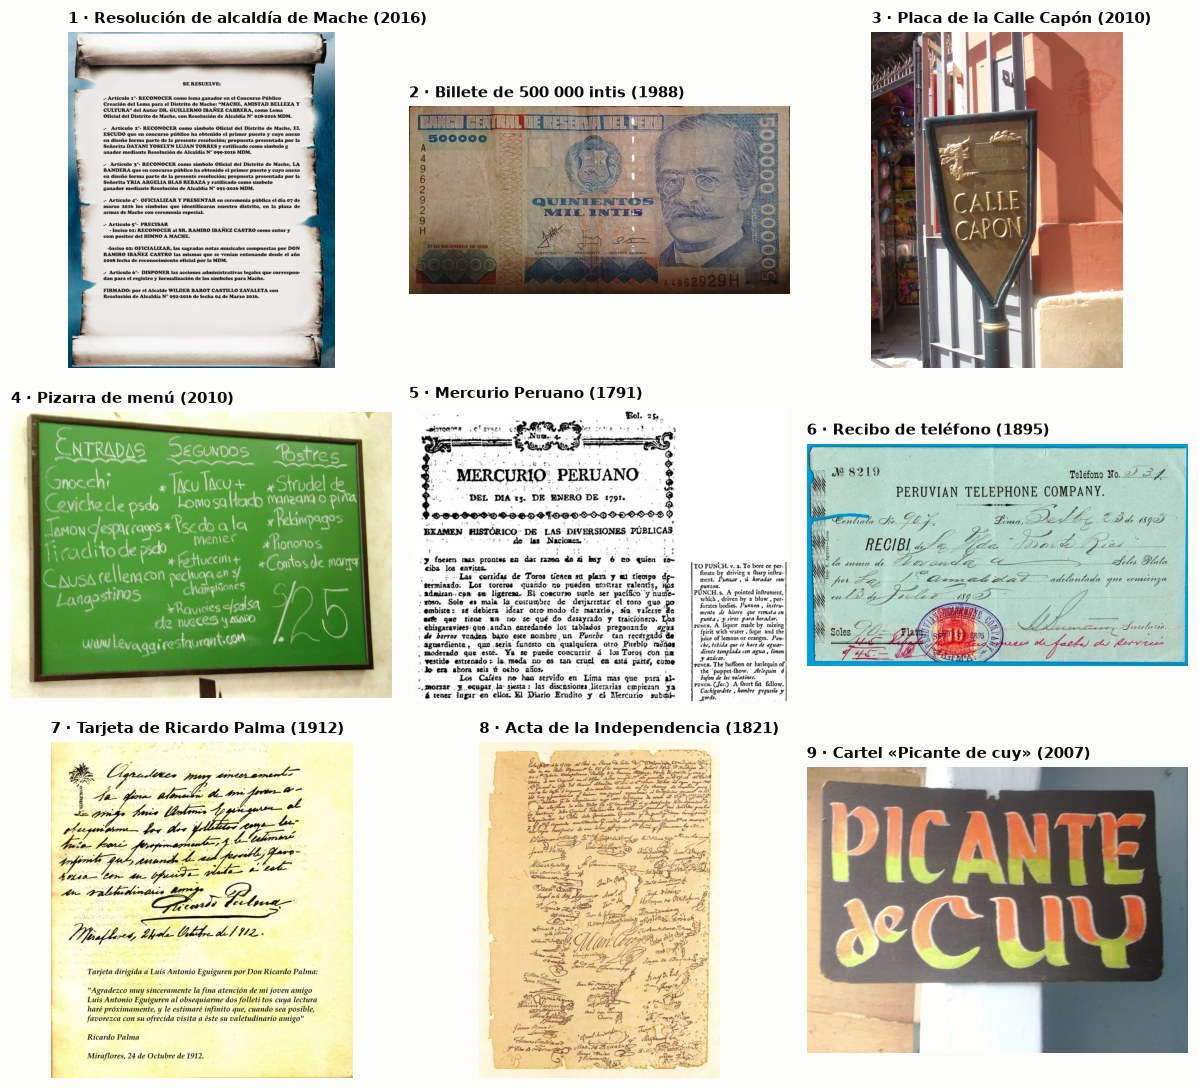

In [5]:
fig, ejes = plt.subplots(3, 3, figsize=(11, 10))
for n, (eje, (clave, d)) in enumerate(zip(ejes.flat, documentos.iterrows()), start=1):
    eje.imshow(Image.open(d.ruta).convert("RGB"))
    eje.set_title(f"{n} · {d.documento} ({d.año})", fontsize=9.5)
    eje.axis("off")
fig.tight_layout()
plt.show()

## 2 · El primer OCR

Crear el modelo es una línea. Las tres opciones en `False` apagan pasos previos que aquí no
necesitamos (enderezar la página, «planchar» hojas dobladas y girar líneas).

In [6]:
OPCIONES = dict(
    use_doc_orientation_classify=False,   # no girar la página completa
    use_doc_unwarping=False,              # no "planchar" hojas dobladas
    use_textline_orientation=False,       # no girar cada línea
)

ocr = PaddleOCR(engine="transformers", **OPCIONES)    # engine="transformers": correr con PyTorch
a_gpu(ocr);

  detector de texto            22.0 millones de parámetros → mps
  reconocedor de texto         19.1 millones de parámetros → mps


`a_gpu` encontró **dos** redes, y no es casualidad. Un OCR clásico trabaja en dos pasos:

1. un **detector** ubica dónde hay texto y dibuja una caja alrededor de cada línea;
2. un **reconocedor** lee, una por una, las letras dentro de cada caja.

El modelo se llama **PP-OCRv6** y un mismo reconocedor cubre 50 idiomas, entre ellos el
español con sus tildes y eñes. Probémoslo con el documento fácil:

In [7]:
resultado = ocr.predict(str(documentos.ruta["resolucion"]))[0]

pd.DataFrame({"texto": resultado["rec_texts"], "confianza": resultado["rec_scores"]}).head(8).round(3)

,texto,confianza
0,SERESUELVE:,0.998
1,.- Artículo 1°- RECONOCER como lema ganador en el Concurso Público,0.988
2,"Creación del Lema para el Distrito de Mache: ""MACHE, AMISTAD BELLEZA Y",0.993
3,"CULTURA"" del Autor DR. GUILLERMO IBAÑEZ CABRERA, como Lema",0.987
4,"Oficial del Distrito de Mache, con Resolución de Alcaldía N° o18-2o16 MDM.",0.995
5,".- Articulo 2°- RECONOCER como símbolo Oficial del Distrito de Mache, EL",0.976
6,ESCUDO que en concurso público ha obtenido el primer puesto y cuyo anexo,0.993
7,en diseño forma parte de la presente resolución; propuesta presentada por la,1.000


Cada fila es una línea de texto, con dos datos:

- **texto**: lo que leyó el reconocedor (viene en `rec_texts`);
- **confianza**: qué tan seguro está, de 0 a 1 (viene en `rec_scores`).

El resultado trae además las coordenadas de cada caja (`rec_boxes`). Las tildes, las eñes y
el «N°» salen bien, pero hay tres tropiezos que vale la pena mirar:

- fila 0: pegó dos palabras, «SERESUELVE:»;
- fila 5: perdió una tilde, «Articulo»;
- fila 4: leyó **«o18-2o16»** donde el documento dice 018-2016, y lo hizo con confianza 0.995.

El último no es un descuido. Esta tipografía dibuja el cero pequeño y redondo, idéntico a una
«o». Primera lección de la clase: **una confianza alta no garantiza un dato correcto**, y los
números son justo lo que más cuesta confundir.

Guardamos estos pasos en una función para reutilizarla:

In [8]:
def leer(ruta, modelo=None):
    "OCR de una imagen. Devuelve una tabla con una fila por cada línea de texto."
    r = (ocr if modelo is None else modelo).predict(str(ruta))[0]
    cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4)          # x0, y0, x1, y1 de cada línea
    return pd.DataFrame({
        "texto": r["rec_texts"],
        "confianza": np.round(r["rec_scores"], 3),
        "x0": cajas[:, 0], "y0": cajas[:, 1], "x1": cajas[:, 2], "y1": cajas[:, 3],
    })

## 3 · Ver lo que ve el modelo

Dibujemos las cajas del detector sobre la imagen, pintadas según la confianza del reconocedor.
El billete de 500 000 intis es un buen examen: letras ornamentales, texto vertical y un fondo
lleno de dibujos.

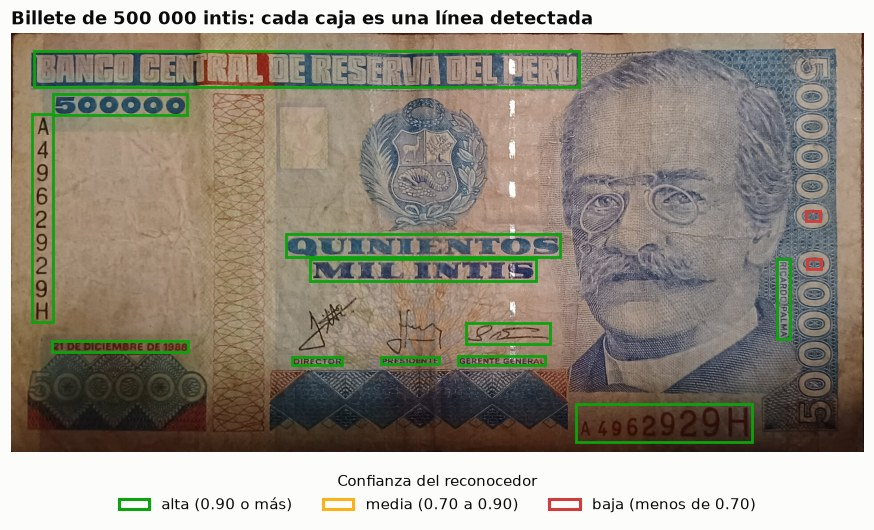

In [9]:
def color_confianza(c):
    return BIEN if c >= 0.90 else DUDA if c >= 0.70 else MAL


LEYENDA = [
    Patch(facecolor="none", edgecolor=BIEN, linewidth=2, label="alta (0.90 o más)"),
    Patch(facecolor="none", edgecolor=DUDA, linewidth=2, label="media (0.70 a 0.90)"),
    Patch(facecolor="none", edgecolor=MAL, linewidth=2, label="baja (menos de 0.70)"),
]


def dibujar(ruta, lineas, eje, titulo=""):
    "Muestra la imagen con una caja por línea detectada, coloreada según su confianza."
    eje.imshow(Image.open(ruta).convert("RGB"))
    for f in lineas.itertuples():
        eje.add_patch(Rectangle((f.x0, f.y0), f.x1 - f.x0, f.y1 - f.y0, fill=False,
                                linewidth=1.8, edgecolor=color_confianza(f.confianza)))
    eje.set_title(titulo)
    eje.axis("off")


billete = leer(documentos.ruta["billete"])

fig, eje = plt.subplots(figsize=(10, 5.2))
dibujar(documentos.ruta["billete"], billete, eje, "Billete de 500 000 intis: cada caja es una línea detectada")
eje.legend(handles=LEYENDA, title="Confianza del reconocedor", loc="upper center",
           bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
plt.show()

In [10]:
billete[["texto", "confianza"]]

,texto,confianza
0,BANCO CENTRAL DE RESERUADELPERU,0.951
1,500000,1.000
2,A4962929H,1.000
3,S,0.662
4,QUINIENTOS,1.000
5,MILINTIS,1.000
6,RICARDOPALMA,1.000
7,ae,0.409
8,85,0.948
9,21 DE DICIEMBRE DE 1988,0.995


- El detector encontró texto en **tres orientaciones**: horizontal, el número de serie en
  columna a la izquierda y «RICARDO PALMA» girado junto al retrato.
- Monto, fecha y número de serie salieron con confianza de 0.99 o más. La serie aparece dos
  veces y las dos lecturas coinciden: `A4962929H`.
- **Los espacios son el punto débil**: «MILINTIS», «RICARDOPALMA» y «RESERUADELPERU», donde
  además la «V» ornamental se leyó como «U».
- Las cajas rojas («S», «ae») son trozos del dibujo de fondo tomados por letras. Su confianza
  es baja, así que se filtran fácil.
- El «500000» grande y vertical del borde derecho no se leyó: solo salieron fragmentos.

El retratado es Ricardo Palma. Nos lo volveremos a encontrar.

## 4 · ¿Vale la pena la GPU?

Leemos la misma página con tres configuraciones y cronometramos. La primera pasada de cada
modelo se descarta: incluye el «calentamiento» y no representa el uso normal.

In [11]:
def cronometrar(modelo, ruta, repeticiones=2):
    "Segundos por página: descarta la primera pasada y se queda con la mejor de las siguientes."
    modelo.predict(str(ruta))
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        modelo.predict(str(ruta))
        tiempos.append(time.perf_counter() - t0)
    return min(tiempos)


pagina = documentos.ruta["resolucion"]

variantes = {
    "PaddlePaddle en CPU (configuración por defecto)": PaddleOCR(device="cpu", **OPCIONES),
    "PyTorch en CPU": PaddleOCR(engine="transformers", device="cpu", **OPCIONES),
}
if DISPOSITIVO != "cpu":
    variantes[f"PyTorch en {DISPOSITIVO.upper()}"] = ocr          # el que ya movimos a la GPU

segundos = pd.Series({nombre: cronometrar(m, pagina) for nombre, m in variantes.items()}, name="segundos por página")
segundos.round(2).to_frame()

,segundos por página
PaddlePaddle en CPU (configuración por defecto),14.97
PyTorch en CPU,6.15
PyTorch en MPS,0.62


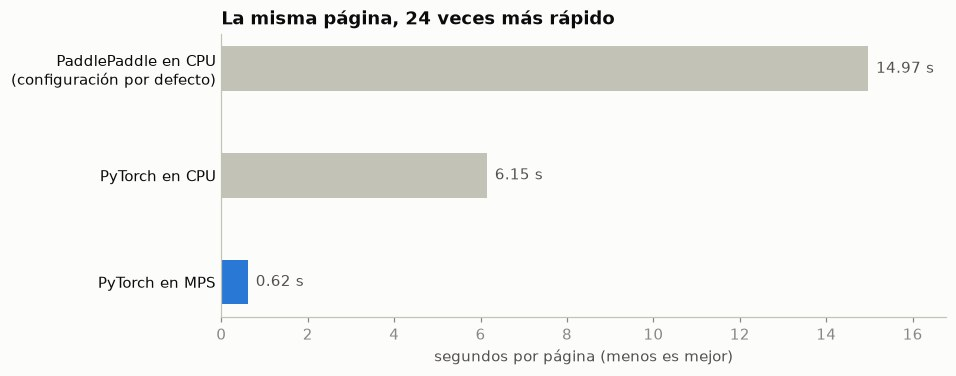

Líneas idénticas entre CPU y MPS: 28 de 28


In [12]:
mas_lento, mas_rapido = segundos.max(), segundos.min()

fig, eje = plt.subplots(figsize=(8.5, 0.75 * len(segundos) + 1.1))
colores = [AZUL if s == mas_rapido else GRIS for s in segundos]
eje.barh([n.replace(" (", "\n(") for n in segundos.index], segundos.values, height=0.42, color=colores)
for i, s in enumerate(segundos):
    eje.text(s + mas_lento * 0.012, i, f"{s:.2f} s", va="center", color=TINTA_2)
eje.invert_yaxis()
eje.set_xlim(0, mas_lento * 1.12)
eje.set_xlabel("segundos por página (menos es mejor)")
eje.tick_params(axis="y", colors=TINTA, length=0)
eje.set_title(f"La misma página, {mas_lento / mas_rapido:.0f} veces más rápido")
plt.show()

# ¿Cambia el texto al cambiar de dispositivo?
en_cpu = leer(pagina, variantes["PyTorch en CPU"]).texto
en_gpu = leer(pagina).texto
print(f"Líneas idénticas entre CPU y {DISPOSITIVO.upper()}: {(en_cpu.values == en_gpu.values).sum()} de {len(en_gpu)}")

del variantes      # liberar memoria: desde aquí solo usamos `ocr`

En la Mac con chip M5 Max donde se preparó esta clase, la página tardó unos 15 s con la
configuración por defecto, 6 s con PyTorch en CPU y 0,6 s en la GPU. Tres cosas para retener:

1. **Cambiar de motor ya ayuda.** PyTorch aprovecha la CPU de Apple mejor que PaddlePaddle:
   más del doble de rápido sin tocar nada más.
2. **La GPU da otro salto de diez veces.** Para un archivo de 10 000 páginas, es la
   diferencia entre casi dos días de cómputo y menos de dos horas.
3. **El texto es idéntico**, línea por línea. La GPU cambia la velocidad, no el resultado.

Si tu máquina tiene una GPU NVIDIA verás `CUDA` en lugar de `MPS`; si no tiene GPU, verás solo
las dos primeras barras, y todo lo que sigue funciona igual, más despacio.

## 5 · La escalera de dificultad

Ahora leemos de una sola vez los ocho documentos de la escalera.

In [13]:
ESCALERA = ["resolucion", "billete", "placa", "menu", "mercurio", "recibo", "palma", "acta"]

t0 = time.perf_counter()
lecturas = {clave: leer(documentos.ruta[clave]) for clave in ESCALERA}
print(f"{len(ESCALERA)} documentos leídos en {time.perf_counter() - t0:.1f} s")

resumen = documentos.loc[ESCALERA, ["documento", "año", "reto"]].copy()
resumen["líneas"] = [len(lecturas[k]) for k in ESCALERA]
resumen["confianza mediana"] = [lecturas[k].confianza.median() for k in ESCALERA]
resumen["% de líneas dudosas"] = [100 * (lecturas[k].confianza < 0.90).mean() for k in ESCALERA]
resumen.round({"confianza mediana": 2, "% de líneas dudosas": 0})

8 documentos leídos en 5.4 s


,documento,año,reto,líneas,confianza mediana,% de líneas dudosas
clave,,,,,,
resolucion,Resolución de alcaldía de Mache,2016,impreso moderno,28,0.99,0.0
billete,Billete de 500 000 intis,1988,tipografía ornamental,14,1.00,14.0
placa,Placa de la Calle Capón,2010,foto en la calle,9,1.00,11.0
menu,Pizarra de menú,2010,letra con tiza,22,0.95,36.0
mercurio,Mercurio Peruano,1791,imprenta colonial,44,0.97,7.0
recibo,Recibo de teléfono,1895,formulario llenado a mano,17,0.84,71.0
palma,Tarjeta de Ricardo Palma,1912,cursiva de puño y letra,12,0.99,42.0
acta,Acta de la Independencia,1821,manuscrito antiguo,46,0.60,96.0


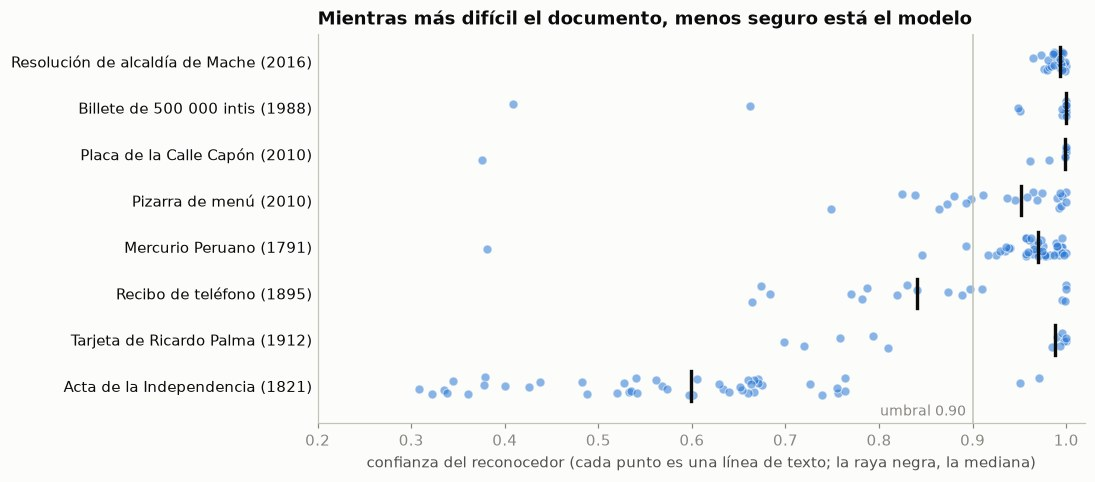

In [14]:
azar = np.random.default_rng(0)

fig, eje = plt.subplots(figsize=(9, 4.6))
for i, clave in enumerate(ESCALERA):
    c = lecturas[clave].confianza.values
    eje.scatter(c, i + azar.uniform(-0.2, 0.2, len(c)), s=34, color=AZUL, alpha=0.55, edgecolor=FONDO, linewidth=0.7)
    eje.plot([np.median(c)] * 2, [i - 0.32, i + 0.32], color=TINTA, linewidth=2.2)
eje.axvline(0.90, color=EJE, linewidth=1)
eje.text(0.893, len(ESCALERA) - 0.45, "umbral 0.90", ha="right", va="center", color=TENUE, fontsize=9)
eje.set_yticks(range(len(ESCALERA)), [f"{resumen.documento[k]} ({resumen.año[k]})" for k in ESCALERA])
eje.tick_params(axis="y", colors=TINTA, length=0)
eje.set_ylim(len(ESCALERA) - 0.2, -0.6)
eje.set_xlim(0.2, 1.02)
eje.set_xlabel("confianza del reconocedor (cada punto es una línea de texto; la raya negra, la mediana)")
eje.set_title("Mientras más difícil el documento, menos seguro está el modelo")
plt.show()

El gráfico cuenta la escalera sin leer una sola palabra:

- En la **resolución**, todos los puntos se apiñan a la derecha.
- En el **billete**, la **placa** y el ***Mercurio***, la mediana sigue arriba, pero aparecen
  puntos sueltos muy a la izquierda: fragmentos que no eran texto.
- En el **menú** y el **recibo**, la nube entera se corre: una de cada tres líneas del menú y
  siete de cada diez del recibo quedan bajo el umbral.
- La **tarjeta de Palma** tiene mediana 0.99 y, sin embargo, 42 % de líneas dudosas. La
  mediana engaña: hay dos grupos, el texto impreso a la derecha y el manuscrito a la izquierda.
- En el **Acta**, casi todo está bajo 0.90.

La confianza funciona como una **alarma**: baja cuando el documento se pone difícil. Veamos
caso por caso qué tan bien avisa.

### 5.1 · Una foto en la calle y una pizarra

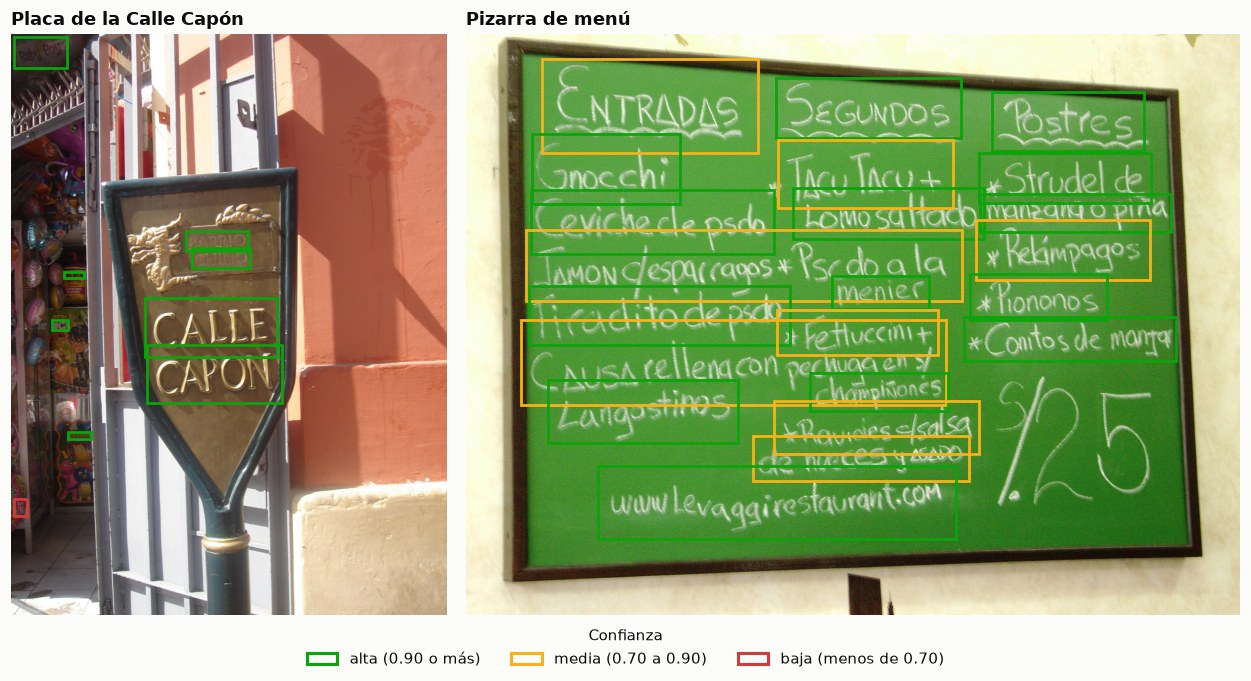

PLACA: Baby Boy · BARRIO · CHINO · GAS HELIO · CALLE · 10 · CAPON · BACKYARDI · 50

MENÚ : ENTRADAS · SEGUNDOS · Postres · Gnocchi · TAcuTacy+ · *Strudelde · Cevicheclepsdo · Lomosaltado · manzangopina · *Rekimpagos · Tmonesparragos*Pscdoala · *Piononos · menier · Tiraditodepsdo · *Fettuccinit · * Conitosdle mangar · reecon · Champinones · Langostinos · #Ravidies/salsa · de nueces y AsaDo · www.levaggirestaurant.com


In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 6), gridspec_kw={"width_ratios": [3, 5.3]})
dibujar(documentos.ruta["placa"], lecturas["placa"], ejes[0], "Placa de la Calle Capón")
dibujar(documentos.ruta["menu"], lecturas["menu"], ejes[1], "Pizarra de menú")
fig.legend(handles=LEYENDA, title="Confianza", loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

print("PLACA:", " · ".join(lecturas["placa"].texto))
print()
print("MENÚ :", " · ".join(lecturas["menu"].texto))

**La placa.** «BARRIO», «CHINO», «CALLE» y «CAPON» salen perfectos, a pesar de la perspectiva
y del relieve dorado. Pero el modelo también leyó lo que nadie le pidió: «Baby Boy» y
«GAS HELIO», de los globos de la tienda vecina. Un OCR lee **todo** el texto de la escena;
separar lo que importa (por posición, por tamaño, por contenido) es trabajo nuestro.

**La pizarra.** Las palabras sueltas salen bien («Gnocchi», «Langostinos», la dirección
web), pero aparecen tres problemas típicos de la letra a mano:

1. **Palabras pegadas**: «Cevicheclepsdo», «Tiraditodepsdo», «Lomosaltado».
2. **Columnas mezcladas**: fíjate en las cajas amarillas anchas. Una sola caja abarca
   «Jamón c/espárragos» y «Pscdo a la», que son de columnas distintas.
3. **El precio no existe.** El «S/. 25», lo primero que buscaría un economista, no tiene
   caja: el detector no lo vio.

El tercero es el más serio. Lo que el detector no ve **no aparece con confianza baja:
simplemente falta**, y ninguna alarma suena.

### 5.2 · Imprenta de 1791

In [16]:
lecturas["mercurio"][["texto", "confianza"]].iloc[:18]

,texto,confianza
0,Eol. 25.,0.846
1,MERCURIO PERUANO,0.994
2,DEL DIA 13. DE ENERO DE 1791.,0.975
3,の,0.381
4,EXAMEN HISTÓRICO DE LAS DIVERSIONES PÚBLICAS,0.978
5,de las Naciones.,0.992
6,fnesen mas prontos en dar razon do si kay ó no quíen te-,0.893
7,ciba los envites.,0.990
8,TO PUNCH. v. a. To bore or per-,0.995
9,Las corzidas de Toros tienen sn plaza y ai tiempo de-,0.940


Para tener más de dos siglos, se lee sorprendentemente bien. Cuatro cosas que notar:

- **Columnas intercaladas.** La imagen trae pegado, a la derecha, un recorte de un
  diccionario inglés-español de la época. Desde la fila 8 se alternan una línea del periódico
  y una del diccionario: el OCR ordena por altura en la página, sin entender que son dos textos.
- **La ese larga.** En las filas 10 y 15 leyó «fharp inftru-» e «inftrument». En el siglo
  XVIII la «s» se imprimía «ſ», casi idéntica a una «f».
- **Tinta corrida.** «corzidas» por corridas, «sn plaza» por su plaza, «coscurgo» por concurso.
- **No todo lo raro es un error.** «quando» y «razon» están bien leídos: así se escribía
  en 1791. Para evaluar un OCR se compara contra lo que dice el papel, no contra el español de hoy.

La fila 3 es una curiosidad: un adorno tipográfico leído como un carácter japonés, con
confianza 0.38. El modelo cubre 50 idiomas y a veces se le nota.

### 5.3 · Un formulario llenado a mano

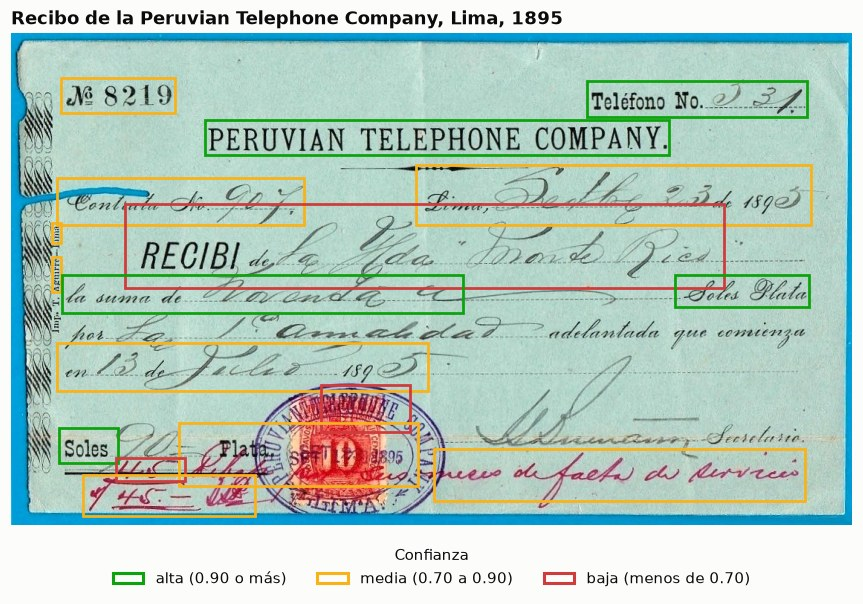

,texto,confianza
0,N 8219,0.830
1,Teléfono No.3,0.996
2,PERUVIAN TELEPHONE COMPANY.,1.000
3,"Lima, Pele 2de 189",0.841
4,Contrata Ko. J0F.,0.874
5,REC1B1 da de Sante Ris,0.664
6,ima,0.889
7,Agirre,0.897
8,la suma de Nor enda a,0.910
9,Soles Plata,0.999


In [17]:
fig, eje = plt.subplots(figsize=(10, 5.8))
dibujar(documentos.ruta["recibo"], lecturas["recibo"], eje, "Recibo de la Peruvian Telephone Company, Lima, 1895")
eje.legend(handles=LEYENDA, title="Confianza", loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
plt.show()

lecturas["recibo"][["texto", "confianza"]]

Esto es lo que dice el recibo, leído por una persona (la tinta roja cuesta incluso a ojo):

| Campo | Contenido |
|---|---|
| Recibo N.º | 8219 |
| Teléfono N.º | 531 |
| Contrata N.º | 907 |
| Fecha | Lima, 23 de setiembre de 1895 |
| Recibí de | la Hda. «Monte Rico» |
| La suma de | noventa soles plata |
| Por | la 1.ª anualidad adelantada, que comienza el 13 de julio de 1895 |
| Anotación en tinta roja | rebaja de 45 por seis meses de falta de servicio |

Lo **impreso** sale perfecto: «PERUVIAN TELEPHONE COMPANY.» y «Soles Plata», con confianza
1.00. Lo **escrito a pluma**, no: «Contrata Ko. J0F.» por *Contrata No. 907*,
«REC1B1 da de Sante Ris» por *RECIBI de la Hda. Monte Rico*, «en13 de Jeileo 1892» por
*en 13 de Julio 1895*.

Aquí la alarma sí suena: casi todas las líneas manuscritas quedan bajo 0.90. Un formulario
real se procesa así: lo impreso entra directo y lo dudoso va a revisión humana.

De paso, el recibo cuenta una historia que le sonará a cualquiera: en 1895 a la hacienda le
descontaron la mitad de la anualidad por medio año sin servicio telefónico.

### 5.4 · El límite: un manuscrito de 1821

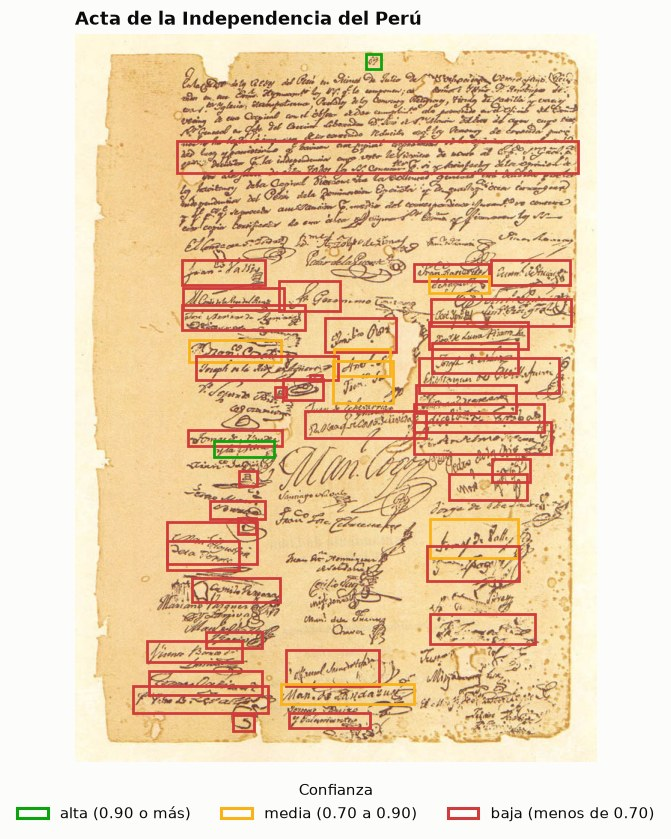

Primeras líneas leídas: 69 · De  iein a oeie de mo a · juian-dalliy · eran.Hanerte · Gunn tu · dehagidf · MCosea Regaalhing · Fr. Gono · oi Werinee Roin · So


In [18]:
fig, eje = plt.subplots(figsize=(6.5, 8.6))
dibujar(documentos.ruta["acta"], lecturas["acta"], eje, "Acta de la Independencia del Perú")
eje.legend(handles=LEYENDA, title="Confianza", loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
plt.show()

print("Primeras líneas leídas:", " · ".join(lecturas["acta"].texto.iloc[:10]))

Casi todas las cajas están en rojo y el texto no se parece a ningún idioma. Solo un par
sale en verde, y una de ellas es el «69» de arriba, el número de folio.

El modelo no sabe leer esto, **y lo dice**: su confianza mediana ronda 0.60. Es exactamente
el comportamiento que uno quiere de una herramienta: que falle avisando.

## 6 · Medir el error

«Se ve bastante bien» no es una medida. La métrica estándar del OCR es la **tasa de error de
caracteres** (CER, por sus siglas en inglés):

$$\text{CER} = \frac{\text{ediciones necesarias para corregir el texto leído}}{\text{caracteres del texto correcto}}$$

Una *edición* es insertar, borrar o cambiar un carácter (la distancia de Levenshtein). Un CER
de 0 % es una lectura perfecta; uno de 5 % significa un error cada veinte caracteres.

In [19]:
def ediciones(a, b):
    "Distancia de Levenshtein: mínimo de inserciones, borrados y cambios para convertir a en b."
    fila = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        nueva = [i]
        for j, cb in enumerate(b, start=1):
            nueva.append(min(fila[j] + 1, nueva[j - 1] + 1, fila[j - 1] + (ca != cb)))
        fila = nueva
    return fila[-1]


def cer(leido, correcto):
    "Tasa de error de caracteres, sin distinguir mayúsculas ni espacios repetidos."
    leido, correcto = " ".join(leido.lower().split()), " ".join(correcto.lower().split())
    return ediciones(leido, correcto) / len(correcto)


print(f"{cer('Rcardo Palrna', 'Ricardo Palma'):.0%}")     # falta una 'i' y la 'm' se leyó 'rn'

23%


Para medir necesitamos un texto de referencia escrito por una persona. La tarjeta de Ricardo
Palma nos regala un experimento limpio: **el mismo mensaje aparece dos veces**, arriba de puño
y letra y abajo transcrito a imprenta. Mismo papel, mismo escaneo, casi el mismo texto; lo
único que cambia es quién lo escribió.

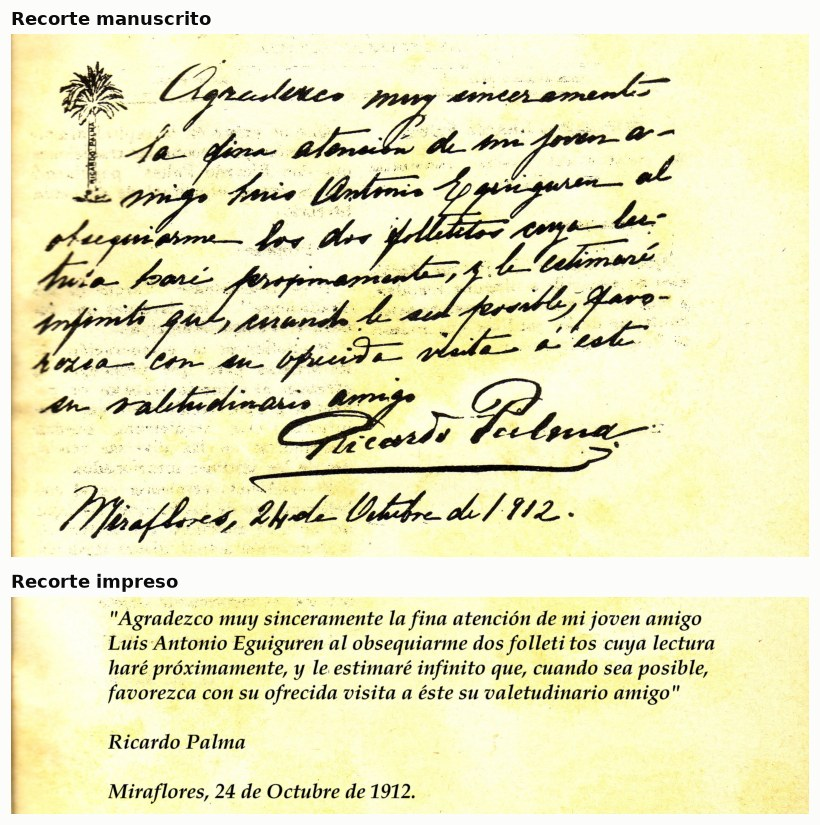

In [20]:
tarjeta = Image.open(documentos.ruta["palma"]).convert("RGB")
ancho, alto = tarjeta.size

recortes = {
    "manuscrito": tarjeta.crop((0, int(0.03 * alto), ancho, int(0.62 * alto))),
    "impreso": tarjeta.crop((0, int(0.715 * alto), ancho, int(0.96 * alto))),
}
rutas_palma = {}
for nombre, imagen in recortes.items():
    rutas_palma[nombre] = DATOS / f"palma_{nombre}.png"
    imagen.save(rutas_palma[nombre])

fig, ejes = plt.subplots(2, 1, figsize=(8.5, 7.6), gridspec_kw={"height_ratios": [1227, 509]})
for eje, (nombre, imagen) in zip(ejes, recortes.items()):
    eje.imshow(imagen)
    eje.set_title(f"Recorte {nombre}")
    eje.axis("off")
fig.tight_layout()
plt.show()

In [21]:
# Transcripciones hechas a mano para esta clase, línea por línea, tal como están escritas.
# Ojo: el manuscrito dice "los dos folletos" y "cuando le sea posible"; la versión impresa no.
CORRECTO = {
    "manuscrito": '''
        Agradezco muy sinceramente
        la fina atención de mi joven a-
        migo Luis Antonio Eguiguren al
        obsequiarme los dos folletos cuya lec-
        tura haré próximamente, y le estimaré
        infinito que, cuando le sea posible, favo-
        rezca con su ofrecida visita á este
        su valetudinario amigo
        Ricardo Palma
        Miraflores, 24 de Octubre de 1912.
    ''',
    "impreso": '''
        "Agradezco muy sinceramente la fina atención de mi joven amigo
        Luis Antonio Eguiguren al obsequiarme dos folleti tos cuya lectura
        haré próximamente, y le estimaré infinito que, cuando sea posible,
        favorezca con su ofrecida visita a éste su valetudinario amigo"
        Ricardo Palma
        Miraflores, 24 de Octubre de 1912.
    ''',
}

palma_ocr = {nombre: " ".join(leer(ruta).texto) for nombre, ruta in rutas_palma.items()}

for nombre, texto in palma_ocr.items():
    print(f"── {nombre}: CER = {cer(texto, CORRECTO[nombre]):.0%}")
    print(f"   {texto}\n")

── manuscrito: CER = 50%
   Agradereo mmy sineeramenls Ta diom alonaidn de on jover a-  Ming, Iris Untmio Epginiguren al gniarme bos do foleeo coma le infimits gut, ruanih b ad peroibl, Gavo- hona con in oprcida slite aest Merafhores, 2hde Dabibre de1912.

── impreso: CER = 1%
   "Ágradezco muy sinceramente la fina atención de mi joven amigo Luis Antonio Eguiguren al obsequiarme dos folleti tos cuya lectura haré próximamente, y le estimaré infinito que, cuando sea posible, favorezca con su ofrecida visita a éste su valetudinario amigo" RicardoPalna Miraflores, 24 de Octubre de 1912.



Mismo papel, mismo escaneo, mismo mensaje:

- **Impreso: 1 %.** Los únicos errores son una tilde inventada («Ágradezco») y la firma,
  «RicardoPalna».
- **Manuscrito: 50 %.** Uno de cada dos caracteres está mal, y además el modelo se saltó
  líneas enteras.

El error se multiplica por cincuenta solo por la caligrafía. Ahora tenemos un número para
comparar modelos, en lugar de una impresión.

## 7 · Otra familia de modelos: PaddleOCR-VL

PP-OCRv6 lee letra por letra dentro de cada caja, sin saber qué dice el resto de la página.
**PaddleOCR-VL** es otra cosa: un **modelo de visión-lenguaje** de 900 millones de parámetros
que mira un bloque del documento y *escribe* su contenido, como lo haría un LLM. Primero una
red ubica los bloques (títulos, párrafos, tablas, imágenes) y después el modelo de lenguaje
redacta cada uno.

Es unas veinte veces más grande que PP-OCRv6, así que aquí la GPU deja de ser un lujo.

In [22]:
vlm = PaddleOCRVL(engine="transformers", use_doc_orientation_classify=False, use_doc_unwarping=False)
a_gpu(vlm);

  detector de bloques          33.2 millones de parámetros → mps


  modelo de visión-lenguaje   905.6 millones de parámetros → mps


In [23]:
def leer_vlm(ruta, max_tokens=300):
    "Lee un documento con PaddleOCR-VL. Devuelve el texto y los segundos que tardó."
    t0 = time.perf_counter()
    r = vlm.predict(str(ruta), max_new_tokens=max_tokens)[0]
    texto = r.markdown["markdown_texts"]                    # el modelo responde en Markdown
    texto = re.sub(r"<[^>]+>", " ", texto)                  # quitar etiquetas HTML de imágenes incrustadas
    texto = re.sub(r"^#+\s*", "", texto, flags=re.M)        # quitar las marcas de título
    return " ".join(texto.split()), time.perf_counter() - t0


leer_vlm(rutas_palma["impreso"])      # primera pasada de calentamiento: no la contamos

palma_vlm = {nombre: leer_vlm(ruta)[0] for nombre, ruta in rutas_palma.items()}

errores = pd.DataFrame({
    "PP-OCRv6": {n: cer(palma_ocr[n], CORRECTO[n]) for n in CORRECTO},
    "PaddleOCR-VL": {n: cer(palma_vlm[n], CORRECTO[n]) for n in CORRECTO},
}).loc[["impreso", "manuscrito"]]

print("PaddleOCR-VL sobre el manuscrito:\n  ", palma_vlm["manuscrito"], "\n")
(100 * errores).round(1).rename_axis("CER (%)")

PaddleOCR-VL sobre el manuscrito:
   Agruculeco may sincerament la giona atonida de mi foron a la migo toco Antonio Eguiguren al otuguiarme los dos folletos coma las tuvia faro formamado, y la calimori infinito que, enุando la aprobable, faro hoxa con un opicido visita a el en saludimario amigo Pico de Foulona Miraflores, 24de Outre de 1912. 



,PP-OCRv6,PaddleOCR-VL
CER (%),,
impreso,1.0,0.0
manuscrito,49.5,30.3


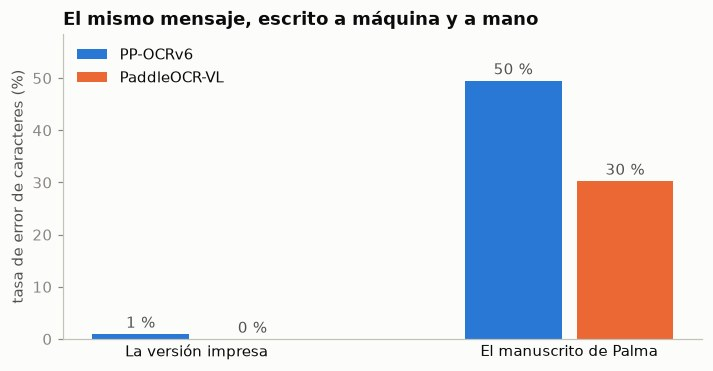

In [24]:
fig, eje = plt.subplots(figsize=(7.5, 3.6))
posiciones = np.arange(len(errores))
for k, (modelo, color) in enumerate([("PP-OCRv6", AZUL), ("PaddleOCR-VL", NARANJA)]):
    x = posiciones + (k - 0.5) * 0.3
    eje.bar(x, 100 * errores[modelo], width=0.26, color=color, label=modelo)
    for xi, v in zip(x, 100 * errores[modelo]):
        eje.text(xi, v + 1.2, f"{v:.0f} %", ha="center", color=TINTA_2)
eje.set_xticks(posiciones, ["La versión impresa", "El manuscrito de Palma"])
eje.tick_params(axis="x", colors=TINTA, length=0)
eje.set_ylabel("tasa de error de caracteres (%)")
eje.set_ylim(0, 100 * errores.values.max() * 1.18)
eje.legend(frameon=False, loc="upper left")
eje.set_title("El mismo mensaje, escrito a máquina y a mano")
plt.show()

PaddleOCR-VL baja el error del manuscrito de 50 % a 30 %, y en el impreso no falla un solo
carácter. Mejora, pero sigue lejos de servir: 30 % es casi un carácter de cada tres.

Lo interesante es **cómo** se equivoca. Acierta «los dos folletos», «Antonio Eguiguren» y el
año. Pero mira el resto:

- «Pico de Foulona» donde firma *Ricardo Palma*;
- «saludimario amigo» por *valetudinario amigo*;
- «la aprobable» por *le sea posible*;
- y en medio de una palabra, una vocal del alfabeto tailandés.

PP-OCRv6 fallaba con basura evidente («sineeramenls»). El modelo de lenguaje falla con
palabras que **parecen español**, porque está entrenado para escribir texto que suene
plausible. Ese error es más difícil de detectar.

### 7.1 · Cada modelo tiene su terreno

Comparemos los dos modelos en cuatro documentos muy distintos.

In [25]:
def comparar(clave):
    d = documentos.loc[clave]
    t0 = time.perf_counter()
    clasico = " · ".join(leer(d.ruta).texto) or "(no detectó ningún texto)"
    t_clasico = time.perf_counter() - t0
    visual, t_visual = leer_vlm(d.ruta)
    print(f"━━ {d.documento} ({d.año})")
    print(f"   PP-OCRv6     [{t_clasico:4.1f} s]  {clasico[:330]}")
    print(f"   PaddleOCR-VL [{t_visual:4.1f} s]  {(visual or '(no devolvió texto: trató la foto como una imagen)')[:330]}\n")


for clave in ["cuy", "placa", "recibo", "menu"]:
    comparar(clave)

━━ Cartel «Picante de cuy» (2007)
   PP-OCRv6     [ 0.2 s]  (no detectó ningún texto)
   PaddleOCR-VL [ 0.7 s]  PICANTE de CUY



━━ Placa de la Calle Capón (2010)
   PP-OCRv6     [ 0.3 s]  Baby Boy · BARRIO · CHINO · GAS HELIO · CALLE · 10 · CAPON · BACKYARDI · 50
   PaddleOCR-VL [ 0.6 s]  (no devolvió texto: trató la foto como una imagen)



━━ Recibo de teléfono (1895)
   PP-OCRv6     [ 0.1 s]  N 8219 · Teléfono No.3 · PERUVIAN TELEPHONE COMPANY. · Lima, Pele 2de 189 · Contrata Ko. J0F. · REC1B1 da de Sante Ris · ima · Agirre · la suma de Nor enda a · Soles Plata · en13 de Jeileo 1892 · CLORMINE · Soles · Plate95 · 14.5 · pree de faeta da dervicis · 145.
   PaddleOCR-VL [ 1.5 s]  PERUVIAN TELEPHONE COMPANY. Contrata No. 907, Lima,� 23 de 1893 RECIBI de la Yda "Mont Rics" la suma de Novenda u Solos Plata por La Amalida adelantada que comienza en 13 de Julio 189 Soles Plata SEPT 10 PESQUIVANDO COMPANY LIMA



━━ Pizarra de menú (2010)
   PP-OCRv6     [ 0.3 s]  ENTRADAS · SEGUNDOS · Postres · Gnocchi · TAcuTacy+ · *Strudelde · Cevicheclepsdo · Lomosaltado · manzangopina · *Rekimpagos · Tmonesparragos*Pscdoala · *Piononos · menier · Tiraditodepsdo · *Fettuccinit · * Conitosdle mangar · reecon · Champinones · Langostinos · #Ravidies/salsa · de nueces y AsaDo · www.levaggirestaurant.com
   PaddleOCR-VL [ 2.1 s]  CNTRADAS SEGUNDOS Postres Levichele psco Tacu Tacu + Strudel de Lomo saltado manzana o pina Jamon gesparragos * Psc do a la menier iradito de pido -DUSΔ rellenącon pechuącą en s/Langostinos champiñones *Rekimpagos *Piononos *Comitos de manger *Ravioies/salsa de nueces y $ \Delta $ADO www.levaggirestaurant.com 125



| Documento | Lee mejor | Qué pasó |
|---|---|---|
| Cartel «Picante de cuy» | PaddleOCR-VL | PP-OCRv6 no detectó nada: su detector no reconoce como texto esas letras pintadas a dos colores |
| Placa de la Calle Capón | PP-OCRv6 | PaddleOCR-VL clasificó toda la foto como «imagen» y no leyó nada: está hecho para documentos, no para escenas |
| Recibo de 1895 | PaddleOCR-VL, con reservas | Lee «Contrata No. 907» y «en 13 de Julio», pero inventa «PESQUIVANDO» a partir del sello y omite el número de recibo |
| Pizarra de menú | ninguno | PaddleOCR-VL separa bien las palabras («Tacu Tacu», «Lomo saltado», «champiñones») pero mezcla columnas, agrega símbolos raros y lee el precio como «125» |

Y en todos los casos PaddleOCR-VL tarda varias veces más, incluso con GPU.

**No hay un ganador universal.** La pregunta útil no es «¿cuál es el mejor OCR?», sino
«¿cuál sirve para *mi* tipo de documento?», y solo se responde probando con una muestra.

### 7.2 · Cuando un modelo de lenguaje no sabe, inventa

Volvamos al Acta de la Independencia. PP-OCRv6 la leyó mal, pero **avisó**: casi todas sus
líneas salieron con confianza baja. ¿Qué hace un modelo de lenguaje ante el mismo documento?

In [26]:
# max_tokens bajo a propósito: sin ese tope, en este documento el modelo sigue escribiendo durante minutos.
invento, segundos_acta = leer_vlm(documentos.ruta["acta"], max_tokens=96)

print(f"PaddleOCR-VL ({segundos_acta:.1f} s):\n   {invento}\n")
print(f"PP-OCRv6: confianza mediana de {lecturas['acta'].confianza.median():.2f} en {len(lecturas['acta'])} líneas")

PaddleOCR-VL (1.1 s):
   Edo was only a city of Okinwa to stand on the长江. The Okinawa River was a red river,

PP-OCRv6: confianza mediana de 0.60 en 46 líneas


Dos frases en inglés fluido, con dos caracteres chinos, sobre un río en Okinawa. **Nada de
eso está en el Acta de la Independencia del Perú.** Y el resultado no trae ningún número de
confianza que lo delate. A esto se le llama *alucinación*.

| | OCR clásico (PP-OCRv6) | Visión-lenguaje (PaddleOCR-VL) |
|---|---|---|
| Cuando no puede leer | devuelve basura evidente | devuelve texto fluido e inventado |
| ¿Avisa? | sí, con una confianza por línea | no |
| Ubicación del texto | una caja por línea | una caja por bloque |
| Velocidad en GPU | décimas de segundo por página | segundos por página |
| Su terreno | impresos, fotos, grandes volúmenes | manuscritos legibles, rótulos, documentos con estructura |

Regla práctica: si el dato va a entrar a una base **sin que nadie lo revise**, prefiere el
modelo que sabe decir «no estoy seguro».

**¿Y sin GPU?** PaddleOCR-VL en CPU es impracticable: una lectura del recibo de 1895 tardó
38 s en la CPU de una MacBook Pro M5 Max, contra 1,4 s en su GPU. Si quieres
comprobarlo en tu máquina, cambia `False` por `True` (y ten paciencia).

In [27]:
MEDIR_VLM_EN_CPU = False

if MEDIR_VLM_EN_CPU and DISPOSITIVO != "cpu":
    for red in redes(vlm):
        red.to("cpu")
    leer_vlm(documentos.ruta["recibo"])                                   # calentamiento
    print(f"CPU: {leer_vlm(documentos.ruta['recibo'])[1]:.1f} s")
    for red in redes(vlm):
        red.to(DISPOSITIVO)
    leer_vlm(documentos.ruta["recibo"])                                   # calentamiento
    print(f"{DISPOSITIVO.upper()}: {leer_vlm(documentos.ruta['recibo'])[1]:.1f} s")

## 8 · De píxeles a datos: la hiperinflación en once billetes

El objetivo del OCR casi nunca es el texto: es la **tabla** que sale de él. Entre 1987 y 1990
el Banco Central de Reserva tuvo que emitir billetes cada vez más grandes. Wikimedia Commons
tiene fotos de once de ellos. ¿Podemos reconstruir la serie leyendo solo las imágenes?

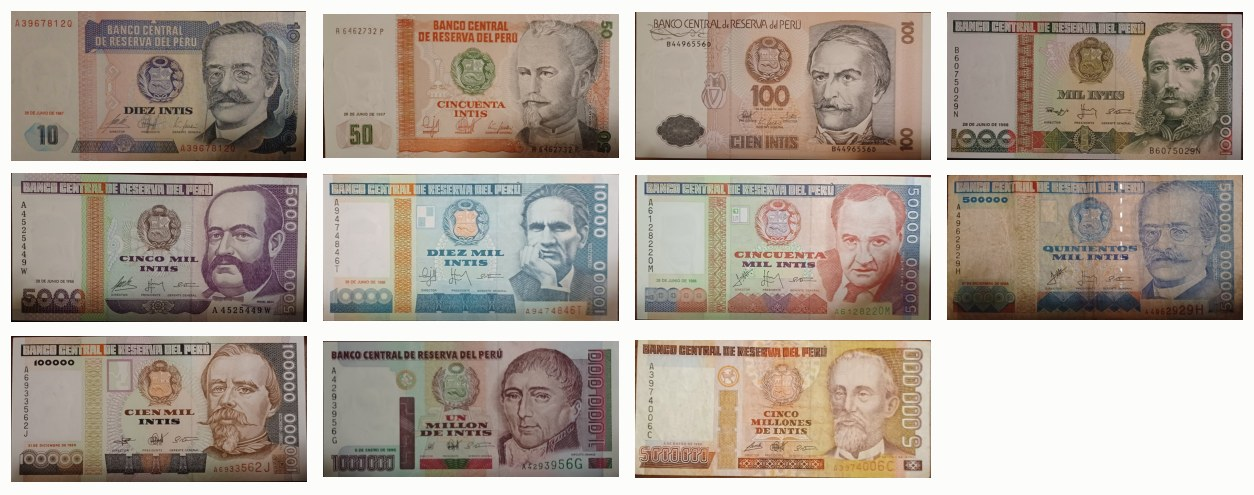

In [28]:
BILLETES = ["10 Intis 1987(front).jpg", "50 Intis 1987(Front).jpg", "100 Intis 1987(Front).jpg",
            "1000 Intis 1988(Front).jpg", "5000 Intis 1988(Front).jpg", "10000 Intis 1988(Front).jpg",
            "50000 Intis 1988(Front).jpg", "500000 Intis 1988(Front).jpg", "100000 Intis 1989(Front).jpg",
            "1000000 Intis 1990(Front).jpg", "5000000 Intis 1990(Front).jpg"]

rutas_billetes = {a: descargar(a, DATOS / f"inti_{a.split(' ')[0]}.jpg") for a in BILLETES}

fig, ejes = plt.subplots(3, 4, figsize=(11.5, 4.6))
for eje in ejes.flat:
    eje.axis("off")
for eje, (archivo, ruta) in zip(ejes.flat, rutas_billetes.items()):
    eje.imshow(Image.open(ruta).convert("RGB"))
fig.tight_layout()
plt.show()

Antes de extraer nada, miremos el texto crudo de uno de ellos, el de mil intis:

In [29]:
print(" · ".join(leer(rutas_billetes["1000 Intis 1988(Front).jpg"]).texto))

BANCO CENTRAL DERESERVADELPERU · B6075029N · MILINTS · Whifja · S0 · 28 DE JUNIO DE 1988 · DIRECTOR · PRESIDENTE · GERENTE GENERAL · B6075029N


Ahí están los tres datos que nos interesan: el **monto en letras**, la **fecha de emisión** y
el **número de serie**, que aparece dos veces. Los pescamos con expresiones regulares.

El texto no viene limpio: el OCR pegó las palabras y hasta se comió una letra («MILINTS»).
Por eso comparamos sin espacios y aceptamos esa variante.

In [30]:
MESES = {m: i for i, m in enumerate("ENERO FEBRERO MARZO ABRIL MAYO JUNIO JULIO AGOSTO SETIEMBRE OCTUBRE NOVIEMBRE DICIEMBRE".split(), start=1)}
BASE = {"UN": 1, "CINCO": 5, "DIEZ": 10, "CINCUENTA": 50, "CIEN": 100, "QUINIENTOS": 500}
MULTIPLO = {"MIL": 1_000, "MILLON": 1_000_000, "MILLONES": 1_000_000}

MONTO = re.compile(r"(UN|CINCO|DIEZ|CINCUENTA|CIEN|QUINIENTOS)?(MILLONES|MILLON|MIL)?(DE)?(INTI?S)?")
FECHA = re.compile(r"(\d{1,2}) DE ([A-Z]+) DE (\d{4})")
SERIE = re.compile(r"[A-Z]\d{7}[A-Z0-9]")


def leer_billete(ruta):
    "Lee un billete y devuelve su monto, su fecha de emisión y sus números de serie."
    lineas = [t.upper() for t in leer(ruta).texto]
    base = multiplo = fecha = None
    for linea in lineas:
        m = MONTO.fullmatch(linea.replace(" ", ""))
        if m and (m[1] or m[2]):                       # la línea es parte del monto en letras
            base = base or BASE.get(m[1])
            multiplo = multiplo or MULTIPLO.get(m[2])
        f = FECHA.search(linea)
        if f and f[2] in MESES:
            fecha = pd.Timestamp(year=int(f[3]), month=MESES[f[2]], day=int(f[1]))
    series = [s for s in lineas if SERIE.fullmatch(s)]
    return {
        "monto leído": (base or 1) * (multiplo or 1) if (base or multiplo) else None,
        "fecha de emisión": fecha,
        "series leídas": " / ".join(series),
        "series coinciden": len(series) == 2 and series[0] == series[1],
    }


billetes = pd.DataFrame([leer_billete(r) for r in rutas_billetes.values()])
billetes.insert(0, "monto real", [int(a.split(" ")[0]) for a in BILLETES])          # el nombre del archivo dice la verdad
billetes.insert(1, "año real", [int(re.search(r"(19\d\d)", a)[1]) for a in BILLETES])

aciertos_monto = (billetes["monto leído"] == billetes["monto real"]).sum()
aciertos_año = (billetes["fecha de emisión"].dt.year == billetes["año real"]).sum()
print(f"Monto correcto en {aciertos_monto} de {len(billetes)} billetes · año correcto en {aciertos_año} de {len(billetes)}")
billetes

Monto correcto en 11 de 11 billetes · año correcto en 11 de 11


,monto real,año real,monto leído,fecha de emisión,series leídas,series coinciden
0,10,1987,10,1987-06-26,A3967812Q / A39678120,False
1,50,1987,50,1987-06-26,A6462732P / A6462732P,True
2,100,1987,100,1987-06-26,B4496556D / B4496556D,True
3,1000,1988,1000,1988-06-28,B6075029N / B6075029N,True
4,5000,1988,5000,1988-06-28,A4525449W / A4525449W,True
5,10000,1988,10000,1988-06-28,A9474846T / A9474846T,True
6,50000,1988,50000,1988-06-28,A6128220M / A6128220M,True
7,500000,1988,500000,1988-12-21,A4962929H / A4962929H,True
8,100000,1989,100000,1989-12-21,A6933562J / A6933562J,True
9,1000000,1990,1000000,1990-01-05,A4293956G / A4293956G,True


Once de once en el monto y en el año, incluido el billete de «MILINTS»: la expresión regular
tolera esas imperfecciones.

Fíjate en la columna `series coinciden`. En el billete de 10 intis las dos lecturas del
número de serie **no son iguales**: `A3967812Q` y `A39678120`. La correcta es la primera. En
su segunda aparición la «Q» cae sobre el fondo oscuro del retrato y se leyó como un cero, con
confianza 1.00.

Sin mirar la imagen, ya sabíamos que algo andaba mal. Cuando un documento repite un dato,
esa **redundancia es una validación gratuita**. La misma idea sirve para un total que debe
igualar la suma de sus parciales, o para un dígito verificador.

Una advertencia honesta: aquí pudimos comprobar el resultado porque el nombre de cada archivo
dice qué billete es. En un proyecto real esa respuesta no existe, y por eso se valida contra
una muestra transcrita a mano, como hicimos con la tarjeta de Palma.

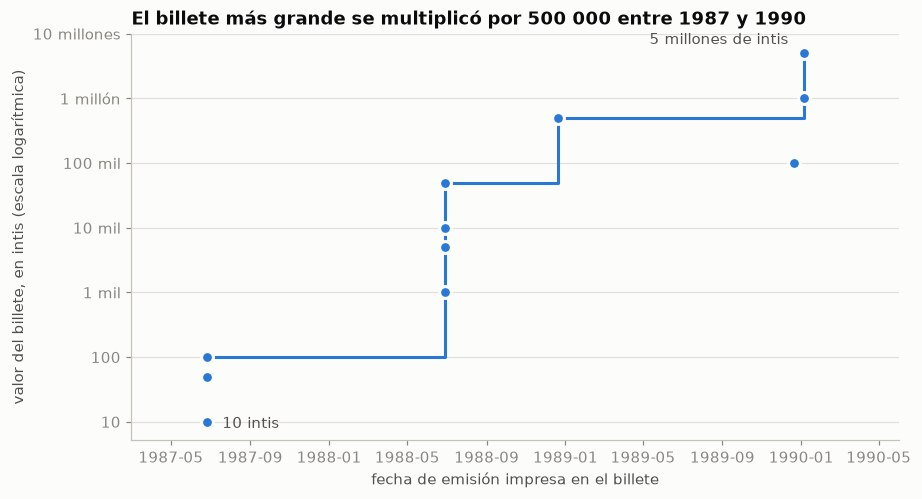

In [31]:
def en_palabras(n):
    return f"{n // 1_000_000} millones" if n >= 2_000_000 else "1 millón" if n >= 1_000_000 else f"{n // 1000} mil" if n >= 1000 else str(n)


serie = billetes.dropna(subset=["monto leído", "fecha de emisión"]).sort_values(["fecha de emisión", "monto leído"])
tope = serie.groupby("fecha de emisión")["monto leído"].max().cummax()       # billete más grande emitido hasta cada fecha

fig, eje = plt.subplots(figsize=(9, 4.8))
eje.step(tope.index, tope.values, where="post", color=AZUL, linewidth=2)
eje.scatter(serie["fecha de emisión"], serie["monto leído"], s=60, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=3)
eje.set_yscale("log")
eje.set_yticks([10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000],
               ["10", "100", "1 mil", "10 mil", "100 mil", "1 millón", "10 millones"])
eje.minorticks_off()
eje.grid(axis="y", color="#e1e0d9", linewidth=0.8)
eje.set_axisbelow(True)
primero, ultimo = serie.iloc[0], serie.iloc[-1]
eje.annotate(f"{en_palabras(primero['monto leído'])} intis", (primero["fecha de emisión"], primero["monto leído"]),
             xytext=(10, -4), textcoords="offset points", color=TINTA_2)
eje.annotate(f"{en_palabras(ultimo['monto leído'])} de intis", (ultimo["fecha de emisión"], ultimo["monto leído"]),
             xytext=(-10, 6), textcoords="offset points", ha="right", color=TINTA_2)
eje.set_xlim(pd.Timestamp("1987-03-01"), pd.Timestamp("1990-06-01"))
eje.set_ylabel("valor del billete, en intis (escala logarítmica)")
eje.set_xlabel("fecha de emisión impresa en el billete")
eje.set_title(f"El billete más grande se multiplicó por {int(ultimo['monto leído'] / primero['monto leído']):,} "
              f"entre {primero['fecha de emisión'].year} y {ultimo['fecha de emisión'].year}".replace(",", " "))
plt.show()

De 10 intis en junio de 1987 a 5 millones en enero de 1990. El eje vertical es logarítmico:
cada escalón de la cuadrícula multiplica por diez.

Para leer el gráfico con cuidado:

- La fecha impresa es la de emisión de la serie, no el día en que el billete empezó a circular.
- El punto suelto de 100 mil lleva fecha de diciembre de 1989, un año **después** que el de
  500 mil: por eso queda debajo de la línea, que marca el billete más grande emitido hasta
  cada momento.
- Once fotos no son un índice de precios. Son, eso sí, una huella muy visible de la
  hiperinflación: en 1991 el nuevo sol reemplazó al inti a razón de un millón de intis por sol.

Lo importante para este curso: **nadie tipeó esa tabla**. Salió de once fotografías.

## 9 · Para llevar

1. **Un OCR clásico hace dos cosas**: detecta dónde hay texto y luego lo reconoce. Devuelve,
   por cada línea, el texto, su caja y una confianza.
2. **La GPU de una Mac sí se puede usar** con PaddleOCR: `engine="transformers"` y mover las
   redes con `.to("mps")`. Mismo texto, más de veinte veces más rápido.
3. **La confianza es una alarma, no una garantía.** Suena ante un manuscrito ilegible, pero
   dejó pasar «o18-2o16» con 0.995, y lo que el detector no ve (el precio del menú) no deja rastro.
4. **Mide, no adivines.** Con una muestra transcrita a mano y el CER pasamos de «se ve bien»
   a «1 % en impreso, 50 % en manuscrito».
5. **Los modelos de visión-lenguaje leen mejor la letra a mano, pero inventan** sin avisar.
   Elige según tu documento y según quién revisará el resultado.
6. **El producto final es una tabla.** Expresiones regulares para extraer campos, y las
   redundancias del propio documento para validarlos.

## Ejercicios

1. **Carteles chicha.** Descarga `Carteles chicha.jpg` de Commons con `descargar(...)` y léelo
   con `leer`. ¿Cuántas líneas detecta? Dibuja las cajas con `dibujar`. ¿Qué tipo de letrero
   recibe menor confianza?
2. **Un modelo de bolsillo.** PP-OCRv6 viene en tres tamaños. Crea uno pequeño con
   `PaddleOCR(engine="transformers", text_detection_model_name="PP-OCRv6_tiny_det", text_recognition_model_name="PP-OCRv6_tiny_rec", **OPCIONES)`,
   muévelo con `a_gpu` y compáralo con el de la clase sobre la resolución de Mache: tiempo
   con `cronometrar` y CER contra una transcripción tuya de las primeras cinco líneas.
3. **Tu propio documento.** Fotografía con el celular una boleta o un recibo de servicios.
   Extrae con una expresión regular el RUC (11 dígitos) y el importe total. ¿Qué confianza
   tienen esas dos líneas?
4. **El reverso.** Los mismos billetes tienen reverso en Commons (`500000 Intis 1988(Reverse).jpg`).
   ¿Qué texto trae? ¿Sirve para validar el monto leído en el anverso?
5. **Un umbral con criterio.** Junta todas las líneas de `lecturas` en una sola tabla. Si
   mandaras a revisión humana toda línea con confianza menor a 0.90, ¿qué porcentaje del
   trabajo tendría que hacer una persona? ¿Y con 0.80?

## Créditos de las imágenes

Todas provienen de [Wikimedia Commons](https://commons.wikimedia.org).

| Imagen | Autor | Licencia |
|---|---|---|
| Resolución de alcaldía de Mache | Helder Zavaleta Verde | CC BY 4.0 |
| Billetes de intis (once anversos) | ByRussia45 | CC0 |
| Placa de la Calle Capón | Miguel Angel Chong | CC BY 3.0 |
| Pizarra de menú del restaurante Levaggi, Lince | Dtarazona | CC BY-SA 3.0 |
| *Mercurio Peruano*, 13 de enero de 1791 | Sociedad Académica de Amantes del País | dominio público |
| Recibo de la Peruvian Telephone Company, 1895 | Peruvian Telephone Company | dominio público |
| Tarjeta de Ricardo Palma a Luis Antonio Eguiguren, 1912 | Ricardo Palma; digitalización de Leguicall | dominio público |
| Acta de la Independencia del Perú, 1821 | Manuel Pérez de Tudela | dominio público |
| Cartel «Picante de cuy», Ingenio, Junín | Dtarazona | dominio público |